# OE5 y OE6: reproducción de los resultados

Tesis «Uso de multi-agentes y su efecto en la calidad metodológica en proyectos de tesis en Ingeniería de la UPAO,
2026-2». Este cuaderno reproduce, **sin llamar a ninguna API**, todas las tablas y pruebas del quinto y del sexto
objetivo específico a partir de los datos anonimizados de `data/`, y muestra al lado el valor reportado en el
informe.

| Objetivo | Qué mide | Datos |
|---|---|---|
| OE5 | Calidad argumentativa (modelo de Toulmin) de la descripción del problema y de la justificación | `data/oe5_secciones.csv`, `data/oe5_retest.csv` |
| OE6 | Proporción de **deficiencias detectadas** por el evaluador en una entrega que se **corrigen** en la siguiente, con respaldo del cambio de texto (diff), GC frente a GE | `data/oe6_items.csv`, `data/oe6_dimensiones.csv` |
| Complemento | Uso de MentorIA en el GE por semana | `data/uso_mentoria_semana.csv` |

**Tres hechos que el estudio distingue:** (a) *deficiencia detectada*: el evaluador califica «no cumple» un criterio;
(b) *observación comunicada*: MentorIA le dio al estudiante una recomendación concreta; (c) *corrección*: el criterio
pasa a «cumple» en la entrega siguiente. **El OE6 mide (a) → (c)**, no (b).

Proyectos: P01–P36 (16 GC y 20 GE), identificadores anónimos. Mediciones: semanas 4, 5, 6, 7 y 9.
Ejecutar con *Entorno de ejecución → Ejecutar todas*. La última sección es opcional y es la única que usa la API.

## 1. Preparación

In [1]:
import os, sys, subprocess
REPO_GITHUB = "prttysav4ge/tesis-oe5-oe6"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not os.path.exists("tesis-oe5-oe6"):
    # Repositorio privado: un token de GitHub de solo lectura, guardado en los Secretos de Colab
    # (icono de la llave, nombre GITHUB_TOKEN) o escrito al ejecutar. Nunca se escribe en el código.
    try:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        from getpass import getpass
        token = getpass("Token de GitHub (solo lectura): ")
    subprocess.run(["git", "clone", "-q", f"https://{token}@github.com/{REPO_GITHUB}.git", "tesis-oe5-oe6"], check=True)
    del token
if os.path.exists("tesis-oe5-oe6"):
    os.chdir("tesis-oe5-oe6")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.path.basename(os.getcwd()))

Carpeta de trabajo: tesis-oe5-oe6


In [2]:
import pandas as pd
from IPython.display import Image, Markdown, display
from src import auditoria, figuras, oe5, oe6, resultados, uso_mentoria
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)
T = resultados.generar_todo()   # todas las tablas quedan también en results/ (CSV) y las figuras en results/figuras/
pd.read_csv("data/muestra.csv").grupo.value_counts()

grupo
GE    20
GC    16
Name: count, dtype: int64

## 2. Auditoría: cada cifra del informe v15 frente al valor recalculado

`valor_informe` es la cifra escrita en el Informe de Tesis v15; `valor_recalculado` sale de `data/` con el código de
`src/`. Las diferencias tienen su explicación en la última columna.

In [3]:
a = T["auditoria_v15"]
print(f"{len(a)} cifras auditadas: {a.coincide.sum()} coinciden; {(~a.coincide).sum()} difieren (todas explicadas).")
display(a[~a.coincide])

96 cifras auditadas: 80 coinciden; 16 difieren (todas explicadas).


,apartado,cifra,valor_informe,valor_recalculado,coincide,explicacion
27,6.5.1,Estructural 2.0 frente a 1.1: mayor / igual / menor (de 138),46 / 75 / 17,46 / 74 / 18,False,Igual que el anterior: el resumen vigente (resumen_OE5_v2.json) da 74 y 18.
30,6.5.2 / Tabla 30,Wilcoxon Descripción del problema Total S4_S5 (aumentos/disminuciones p),15/10 .124,16/9 .069,False,No reproducible con los datos vigentes; ningún archivo de salida conserva el valor del informe. Probablemente se cop...
31,6.5.2 / Tabla 30,Wilcoxon Descripción del problema Total S5_S6 (aumentos/disminuciones p),14/10 .269,15/10 .242,False,No reproducible con los datos vigentes; ningún archivo de salida conserva el valor del informe. Probablemente se cop...
32,6.5.2 / Tabla 30,Wilcoxon Descripción del problema Total S6_S7 (aumentos/disminuciones p),11/14 .611,10/15 .794,False,No reproducible con los datos vigentes; ningún archivo de salida conserva el valor del informe. Probablemente se cop...
36,6.5.2 / Tabla 30,Wilcoxon Descripción del problema GC S4_S5 (aumentos/disminuciones p),.328,.212,False,No reproducible con los datos vigentes; ningún archivo de salida conserva el valor del informe. Probablemente se cop...
37,6.5.2 / Tabla 30,Wilcoxon Descripción del problema GC S5_S6 (aumentos/disminuciones p),.249,.172,False,No reproducible con los datos vigentes; ningún archivo de salida conserva el valor del informe. Probablemente se cop...
38,6.5.2 / Tabla 30,Wilcoxon Descripción del problema GC S6_S7 (aumentos/disminuciones p),.518,.748,False,No reproducible con los datos vigentes; ningún archivo de salida conserva el valor del informe. Probablemente se cop...
56,6.5.2,HE5 DP: Md cambio GE / GC; U; p,3.1 / 2.5; U = 156.5; p = .551,3.2 / 2.5; U = 156.5; p = .551,False,Md GE = 3.15 y Md GC = 2.45: el informe redondea 3.15 hacia abajo y 2.45 hacia arriba. Diferencia de redondeo: el sc...
61,6.5.3,Spearman elaboración-calidad Descripción del problema S4 (ρ p n),.04 .847 33,.03 .847 33,False,ρ = .035: Diferencia de redondeo: el script original redondeaba antes de resumir (la TL de cada proyecto a un decima...
80,6.6.2,Levantadas: total = sustantiva + superficial + sin cambio,577 = 519 + 14 + 43 (suman 576),577 = 520 + 14 + 43,False,Faltaba 1 corrección: estaba en una dimensión sin texto dividido porque la versión anterior de ese proyecto fue «sin...


In [4]:
display(a)  # tabla completa

,apartado,cifra,valor_informe,valor_recalculado,coincide,explicacion
0,6.5.1,Descripciones del problema completas en S4,33,33,True,
1,6.5.1,Justificaciones completas en S4,25,25,True,
2,6.5.1,"Afirmaciones por sección, DP S4 (Md)",5,5,True,
3,6.5.1,"% afirmaciones con dato, DP S4",70.4,70.4,True,
4,6.5.1,"% afirmaciones con garantia, DP S4",6.5,6.5,True,
5,6.5.1,"% afirmaciones con respaldo, DP S4",2.2,2.2,True,
6,6.5.1,"% afirmaciones con calificador, DP S4",5.4,5.4,True,
7,6.5.1,"% afirmaciones con refutacion, DP S4",0.5,0.5,True,
8,6.5.1,"% afirmaciones con dato, JU S4",66.2,66.2,True,
9,6.5.1,"% afirmaciones con garantía, JU S4",5.5,5.5,True,


## 3. OE5: calidad argumentativa (índice argumentativo 2.0)

El índice se calculó con el prompt `src/prompts/argumentacion_toulmin_v2.md` (gpt-4.1, temperatura 0, semilla 42).
Las respuestas del modelo se verificaron con reglas fijas y aquí se usan los indicadores resultantes; el cuaderno no
vuelve a llamar al modelo (la sección 6 muestra una llamada sobre un texto de ejemplo).

**HE5**: U de Mann-Whitney unilateral (GE > GC) del cambio del índice de elaboración entre la primera y la última
medición con la sección completa, con corrección de Holm para las dos secciones.

In [5]:
print("Tabla 29 del informe: perfil de componentes, S4 y S7")
display(T["oe5_tabla29_S4_S7"])
print("Tabla 30 del informe: índice de elaboración y pruebas")
display(T["oe5_tabla30_S4_S7"])
print("Prueba de la HE5 (informe: DP p Holm = .551; JU p = .013, p Holm = .027, δ = .44; se acepta de forma parcial)")
display(T["oe5_he5_S4_S7"])

Tabla 29 del informe: perfil de componentes, S4 y S7


,sección,semana,grupo,n,afirmaciones por sección (Md),% con dato,% con garantia,% con respaldo,% con calificador,% con refutacion,secciones con garantía,índice de elaboración (Md),índice estructural 2.0 (Md),índice estructural 1.1 (Md)
0,Descripción del problema,S4,GC,16,5.5,70.8,5.6,1.1,7.9,0.0,3,18.35,41.65,33.30
1,Descripción del problema,S4,GE,17,5.0,70.1,7.2,3.1,3.1,1.0,7,16.70,50.00,33.30
2,Descripción del problema,S7,GC,16,5.0,81.2,6.9,3.0,1.0,1.0,6,20.00,50.00,33.30
3,Descripción del problema,S7,GE,20,7.0,81.2,8.1,2.7,2.0,0.7,11,20.00,50.00,50.00
4,Justificación,S4,GC,14,7.0,71.6,5.2,1.7,2.6,4.3,3,15.20,41.65,41.65
5,Justificación,S4,GE,11,7.0,58.8,5.9,0.0,1.2,0.0,3,10.00,33.30,33.30
6,Justificación,S7,GC,16,10.5,69.5,2.3,0.9,0.9,1.9,4,15.30,33.30,50.00
7,Justificación,S7,GE,20,7.5,80.8,7.2,3.0,2.4,1.8,8,20.00,41.65,33.30


Tabla 30 del informe: índice de elaboración y pruebas


,sección,grupo,Md S4,Md S5,Md S6,Md S7,"S4-S5: +/−, p","S5-S6: +/−, p","S6-S7: +/−, p",U; p (Holm)
0,Descripción del problema,GC,18.4,20.0,20.0,20.0,"7/4, 0.212","5/1, 0.172","4/7, 0.748",U = 156.5; 0.551 (0.551)
1,Descripción del problema,GE,16.7,20.0,20.0,20.0,"9/5, 0.136","10/9, 0.351","6/8, 0.703",NaN
2,Descripción del problema,Total,16.7,20.0,20.0,20.0,"16/9, 0.069","15/10, 0.242","10/15, 0.794",NaN
3,Justificación,GC,15.2,17.3,18.0,15.3,"5/3, 0.444","1/2, 0.500","3/10, 0.876",U = 230.0; 0.013 (0.027)
4,Justificación,GE,10.0,19.3,20.0,20.0,"8/2, 0.005","11/6, 0.078","6/9, 0.377",NaN
5,Justificación,Total,15.0,18.6,20.0,18.0,"13/5, 0.037","12/8, 0.081","9/19, 0.763",NaN


Prueba de la HE5 (informe: DP p Holm = .551; JU p = .013, p Holm = .027, δ = .44; se acepta de forma parcial)


,índice,sección,n GC / GE,Md cambio GC,Md cambio GE,U,p unilateral,p Holm,δ de Cliff,rechaza H0
0,índice de elaboración (principal),Descripción del problema,16 / 20,2.45,3.15,156.5,0.5507,0.5507,-0.02,False
1,índice de elaboración (principal),Justificación,16 / 20,-1.35,3.10,230.0,0.0134,0.0268,0.44,True
2,índice de elaboración (principal),DECISIÓN,se acepta de forma parcial,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,índice estructural,Descripción del problema,16 / 20,0.00,0.00,149.5,0.6450,0.6450,-0.07,False
4,índice estructural,Justificación,16 / 20,0.00,0.00,200.0,0.0947,0.1894,0.25,False
5,índice estructural,DECISIÓN,no se acepta Hi,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Validez convergente: Spearman entre el índice de elaboración y la calidad de la dimensión en la rúbrica


,semana,seccion,n,rho,p
0,S4,Descripción del problema,33,0.035,0.847
1,S4,Justificación,25,0.018,0.933
2,S5,Descripción del problema,35,0.091,0.603
3,S5,Justificación,35,-0.061,0.727
4,S6,Descripción del problema,34,-0.081,0.647
5,S6,Justificación,35,-0.052,0.769
6,S7,Descripción del problema,36,0.052,0.762
7,S7,Justificación,36,0.216,0.206


Estabilidad test-retest en S4 (informe: 80.6 % funciones iguales, 65.4 % vínculos, CCI = .77 y .77)


,secciones,unidades,funciones_iguales_pct,vinculos_iguales_pct,cci_elaboracion,cci_estructural
0,58,1215,80.576,65.427,0.772,0.766


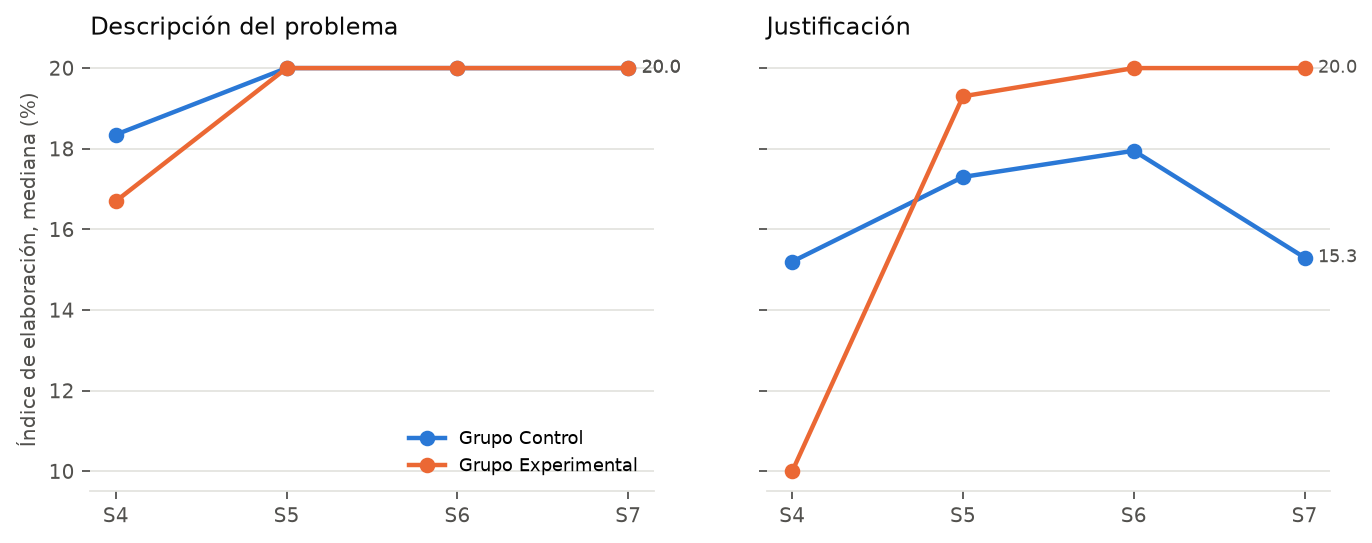

In [6]:
print("Validez convergente: Spearman entre el índice de elaboración y la calidad de la dimensión en la rúbrica")
display(T["oe5_spearman_S4_S7"].round(3))
print("Estabilidad test-retest en S4 (informe: 80.6 % funciones iguales, 65.4 % vínculos, CCI = .77 y .77)")
display(T["oe5_retest"].round(3))
display(Image("results/figuras/oe5_elaboracion_por_semana.png"))

In [7]:
if "oe5_he5_S4_S9" in T:
    print("OE5 con la semana 9 (informe v16)")
    display(T["oe5_tabla30_S4_S9"]); display(T["oe5_he5_S4_S9"])
else:
    print("La semana 9 del OE5 aún no está en data/oe5_secciones.csv.")

La semana 9 del OE5 aún no está en data/oe5_secciones.csv.


## 4. OE6: corrección de las deficiencias detectadas entre entregas consecutivas

- **Deficiencia detectada**: ítem «no cumple» en la entrega *t*, en una dimensión ya redactada en *t*.
- **Corrección**: el ítem pasa a «cumple» en *t+1*. **Retroceso**: un ítem «cumple» pasa a «no cumple».
- **Respaldo textual (diff)**: cada dimensión se compara con su versión anterior (`src/diff_versiones.py`):
  oraciones emparejadas por similitud TF-IDF de lemas con el método húngaro; umbrales τ = .35 y .75 →
  *sin cambio*, *superficial* o *sustantiva*. Una corrección **sin cambio de texto** refleja la variabilidad del
  evaluador sobre el mismo texto.
- **Entrega nominal**: mismo texto que la semana anterior (o sin entrega nueva); conserva la calificación.

En el informe v15 se llama «observación» a la deficiencia detectada y «tasa de levantamiento» (TL) a la tasa de
corrección (TC).

Tabla 31 del informe (por intervalo y grupo)


,intervalo,grupo,entregas_nominales,deficiencias,corregidas,persistentes,TC,cumplidos,retrocesos,TR,corregidas_sin_cambio,corregidas_superficial,corregidas_sustantiva,corregidas_sin_datos
0,S4_S5,GC,1,276,91,185,33.0,507,23,4.5,8,2,81,0
1,S4_S5,GE,3,238,64,174,26.9,494,26,5.3,6,3,55,0
2,S5_S6,GC,11,276,12,264,4.3,668,7,1.0,6,0,6,0
3,S5_S6,GE,0,256,92,164,35.9,680,49,7.2,2,1,89,0
4,S6_S7,GC,1,290,89,201,30.7,680,51,7.5,2,3,84,0
5,S6_S7,GE,3,318,100,218,31.4,1101,34,3.1,8,2,90,0
6,S7_S9,GC,1,288,57,231,19.8,802,39,4.9,6,2,49,0
7,S7_S9,GE,2,260,72,188,27.7,1224,53,4.3,5,1,66,0
8,Total,GC,14,1130,249,881,22.0,2657,120,4.5,22,7,220,0
9,Total,GE,8,1072,328,744,30.6,3499,162,4.6,21,7,300,0


Contraste por intervalo, Holm (informe: 1.000, < .001, 1.000, 1.000)


,intervalo,n_GE,n_GC,Md_GE,Md_GC,M_GE,M_GC,U,p,delta,magnitud,p_holm
0,S4_S5,20,16,28.1579,33.1818,28.1439,32.4945,137.5,0.7685,-0.1406,despreciable,1.0
1,S5_S6,20,16,40.4762,0.0000,36.5544,2.9176,304.0,0.0000,0.9000,grande,0.0
2,S6_S7,20,16,31.5341,30.7292,32.0135,32.7511,159.5,0.5127,-0.0031,despreciable,1.0
3,S7_S9,20,16,18.4066,13.5747,24.8982,18.4392,173.5,0.3386,0.0844,despreciable,1.0


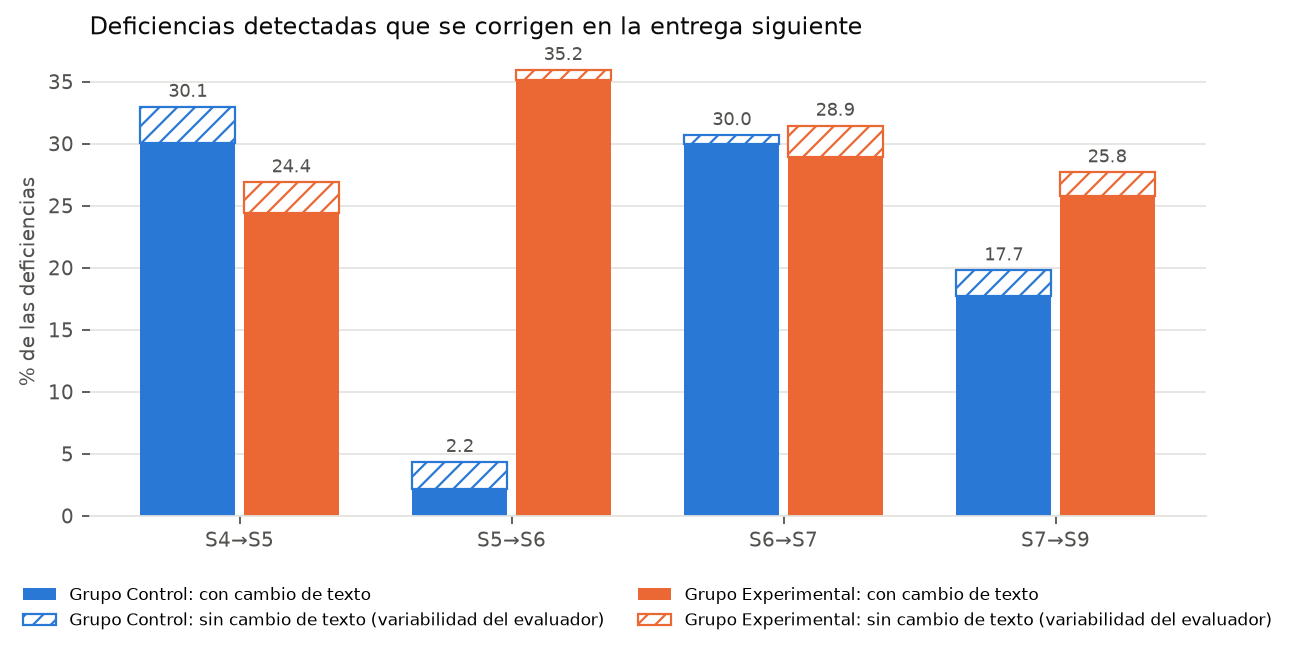

In [8]:
print("Tabla 31 del informe (por intervalo y grupo)")
display(T["oe6_tabla31"].round(1))
print("Contraste por intervalo, Holm (informe: 1.000, < .001, 1.000, 1.000)")
display(T["oe6_por_intervalo"].round(4))
display(Image("results/figuras/oe6_correccion_por_intervalo.png"))

Tabla 32 del informe: corrección según el cambio del texto (entregas reevaluadas)


,clase_cambio,dimensiones,deficiencias,TC,cumplidos,TR,TC_GC,TC_GE
0,sin_cambio,319,515,8.3,1304,2.7,7.9,8.9
1,superficial,48,79,17.7,214,3.3,23.3,14.3
2,sustantiva,721,1276,40.8,3615,6.4,37.2,43.9


Concordancia de las dos medidas del diff: palabras cambiadas por cada 100 (difflib) según la clase por oraciones


,clase_cambio,dimensiones,Md,P25,P75,con_0_palabras
0,sin_cambio,319,0.0,0.0,0.0,306
1,superficial,48,2.4,0.8,14.0,2
2,sustantiva,721,75.8,31.7,108.1,10


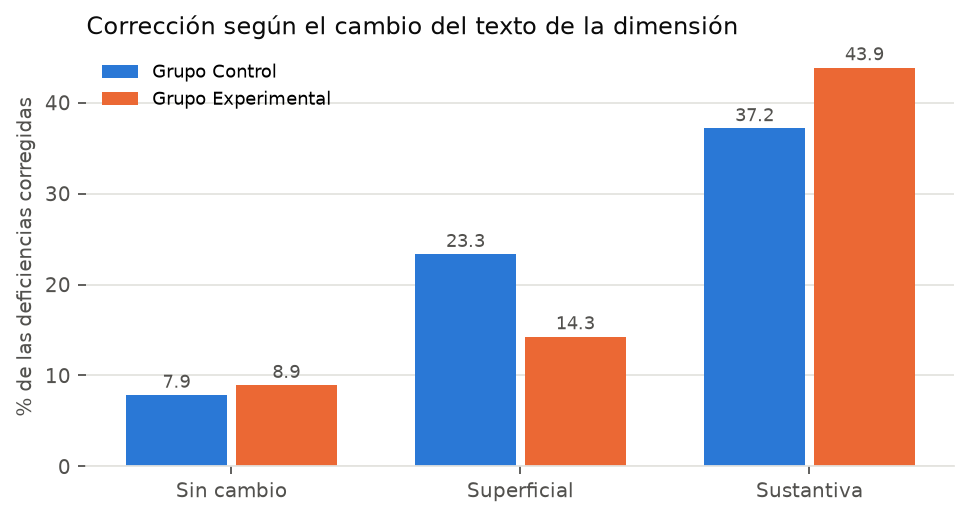

In [9]:
print("Tabla 32 del informe: corrección según el cambio del texto (entregas reevaluadas)")
display(T["oe6_tabla32"].round(1))
print("Concordancia de las dos medidas del diff: palabras cambiadas por cada 100 (difflib) según la clase por oraciones")
display(T["oe6_concordancia_diff"].round(1))
display(Image("results/figuras/oe6_correccion_por_clase_de_cambio.png"))

In [10]:
print("Contraste de la HE6 y sensibilidad.")
print("Informe v15 (fila 'Todas las correcciones'): Md 20.9 frente a 32.3; U = 249.5; p = .002; δ = +0.56")
display(T["oe6_he6_v16"].round(3))
print("Variabilidad del evaluador: correcciones sin cambio de texto, por grupo")
display(T["oe6_variabilidad"].round(1))
print("Retroceso acumulado (bilateral; informe: p = .886)")
display(T["oe6_TR"].round(3))

Contraste de la HE6 y sensibilidad.
Informe v15 (fila 'Todas las correcciones'): Md 20.9 frente a 32.3; U = 249.5; p = .002; δ = +0.56


,analisis,Md_GC,M_GC,Md_GE,M_GE,estadistico,p,efecto,magnitud
0,Principal: corrección con cambio de texto,18.816,21.270,32.338,30.074,U = 241.5,0.005,δ = +0.51,grande
1,Todas las correcciones (contraste principal del v15),20.918,22.827,32.338,32.126,U = 249.5,0.002,δ = +0.56,grande
2,Solo correcciones con revisión sustantiva,17.455,20.601,31.545,29.453,U = 243.0,0.004,δ = +0.52,grande
3,Solo deficiencias de dimensiones revisadas (¿corrigen más cuando revisan?),33.333,35.851,44.097,44.105,U = 223.0,0.023,δ = +0.39,mediano
4,Sin entregas nominales,25.253,26.748,32.381,32.655,U = 210.0,0.057,δ = +0.31,pequeño
5,Sin el intervalo S5-S6 (semana sin asesoría),24.886,27.215,30.101,28.026,U = 176.0,0.311,δ = +0.10,despreciable
6,"Por deficiencia (GEE binomial, corrección con cambio de texto)",NaN,NaN,NaN,NaN,OR = 1.39 [0.98; 1.95],0.031,,


Variabilidad del evaluador: correcciones sin cambio de texto, por grupo


,grupo,deficiencias_reevaluadas,en_dimensiones_sin_cambio,corregidas_sin_cambio,TC_sin_cambio,pct_de_todas_las_correcciones
0,GC,902,280,22,7.9,8.8
1,GE,973,235,21,8.9,6.4


Retroceso acumulado (bilateral; informe: p = .886)


,n_GE,n_GC,Md_GE,Md_GC,M_GE,M_GC,U,p,delta,magnitud
0,20,16,4.897,5.057,4.738,4.814,155.0,0.886,-0.031,despreciable


## 5. MentorIA en el Grupo Experimental: uso y observaciones comunicadas

**5.1 Uso por semana** (registros automáticos; la semana S9 reúne el uso de las semanas 8 y 9).

,semana de uso,proyectos del GE,proyectos con consultas,consultas,consultas por proyecto usuario (Md),revisiones de secciones,revisiones completas,días con consultas,minutos en sesiones con consultas,sesiones sin mensajes
0,S5,20,17,98.0,3.0,12.0,8.0,30,1199.0,71.0
1,S6,20,8,22.0,1.5,0.0,6.0,9,240.0,9.0
2,S7,20,9,72.0,2.0,2.0,13.0,14,701.0,18.0
3,S9,20,2,23.0,11.5,1.0,1.0,3,132.0,6.0


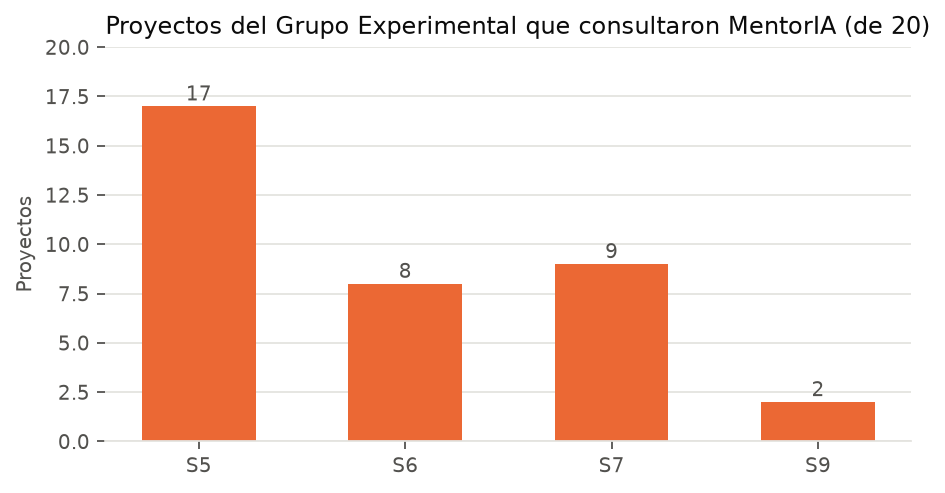

Exploratorio (solo GE, proyecto x intervalo): tasa de corrección con cambio de texto según hubo consultas


,consultas,size,median,mean
0,sin consultas,44,23.1,25.3
1,con consultas,36,30.6,32.4


{'n': 80, 'rho': 0.1390447829779483, 'p': 0.2186722377429852}


In [11]:
display(T["uso_por_semana"])
display(Image("results/figuras/uso_mentoria_por_semana.png"))
print("Exploratorio (solo GE, proyecto x intervalo): tasa de corrección con cambio de texto según hubo consultas")
display(T["uso_y_correccion"].round(1)); print(T["uso_y_correccion_spearman"])

**5.2 De la observación comunicada (b) a la corrección (c).** Cuando un estudiante pidió a MentorIA revisar su
proyecto, el sistema calificó cada criterio de la rúbrica institucional (33 criterios, 0 a 3 puntos) y escribió una
observación. Un criterio calificado por debajo del máximo es una **observación comunicada**. Cada observación se
asocia a la entrega siguiente a su fecha y a la dimensión equivalente del evaluador (`MAPA_ITEMS` en
`src/uso_mentoria.py`); luego se verifica si el evaluador registraba deficiencias en esa dimensión (a) y si se
corrigieron con cambio de texto (c). `data/mentoria_observaciones.csv` no contiene el texto de las observaciones.

In [12]:
print("Observaciones comunicadas por intervalo (n real)")
display(T["obs_por_intervalo"])
print("Seguimiento de cada par proyecto-intervalo-dimensión con observación comunicada")
display(T["vinculo_seguimiento"]); print(T["vinculo_atendidas"])
print("Mismos proyectos y semanas: deficiencias en dimensiones con y sin observación de MentorIA")
display(T["vinculo_comparacion"].round(1)); print("GEE:", T["vinculo_gee"])
print("Sensibilidad sin las observaciones anteriores a la medición de la semana 4")
display(T["vinculo_comparacion_sin_antes_S4"].round(1)); print("GEE:", T["vinculo_gee_sin_antes_S4"])

Observaciones comunicadas por intervalo (n real)


,intervalo,revisiones de MentorIA,proyectos,observaciones comunicadas,con dimensión equivalente,pares proyecto-dimensión
0,S4_S5,12,10,66,59,31
1,S5_S6,6,5,56,33,19
2,S6_S7,14,8,179,138,47
3,S7_S9,2,2,16,15,11


Seguimiento de cada par proyecto-intervalo-dimensión con observación comunicada


,estado,pares
0,corregida con cambio de texto,31
1,dimensión no redactada en la entrega anterior,26
2,no corregida,31
3,sin deficiencias en el evaluador,20


{'pares_con_deficiencia': 62, 'corregidos': 31, 'texto_revisado': 48, 'proyectos': 14}
Mismos proyectos y semanas: deficiencias en dimensiones con y sin observación de MentorIA


,comunicada,deficiencias,corregidas_con_cambio,proyectos,TC_con_cambio
0,sin observación de MentorIA,252,67,13,26.6
1,con observación de MentorIA,149,52,14,34.9


GEE: {'n_observaciones': 401, 'n_proyectos': 14, 'OR': 1.5172628683518097, 'IC95': [0.8443044301163152, 2.72660728709195], 'p_unilateral': 0.08165073050455429}
Sensibilidad sin las observaciones anteriores a la medición de la semana 4


,comunicada,deficiencias,corregidas_con_cambio,proyectos,TC_con_cambio
0,sin observación de MentorIA,183,57,10,31.1
1,con observación de MentorIA,98,40,11,40.8


GEE: {'n_observaciones': 281, 'n_proyectos': 11, 'OR': 1.4916315888656977, 'IC95': [0.793077978785515, 2.8054804904673056], 'p_unilateral': 0.10736520739591776}


## 6. (Opcional) Ver el procedimiento en acción sobre un texto de ejemplo

Los textos de `data/ejemplo_ficticio/` son **ficticios**: no pertenecen a ningún proyecto del estudio.

**6.1 Diff entre dos versiones (sin API).**

In [13]:
from src.diff_versiones import comparar_textos, diff_lineas
leer = lambda f: open(f, encoding="utf-8").read().split("\n", 2)[2]
v1 = leer("data/ejemplo_ficticio/descripcion_problema_v1.txt")
v2 = leer("data/ejemplo_ficticio/descripcion_problema_v2.txt")
r = comparar_textos(v1, v2)
print("Clase de cambio de la dimensión:", r["clase"], "| oraciones:", r["oraciones"],
      f"| palabras cambiadas por cada 100: {r['pct_palabras_cambiadas']:.1f}")
display(pd.DataFrame(r["detalle"], columns=["clase", "versión anterior", "versión nueva"]))
print(diff_lineas(v1, v2))

Clase de cambio de la dimensión: sustantiva | oraciones: {'sin_cambio': 3, 'superficial': 0, 'sustantiva': 1, 'anadida': 5, 'eliminada': 1} | palabras cambiadas por cada 100: 64.1


,clase,versión anterior,versión nueva
0,sin_cambio,"En las pequeñas empresas de panificación de la ciudad, el control del inventario de insumos se realiza de forma manu...","En las pequeñas empresas de panificación de la ciudad, el control del inventario de insumos se realiza de forma manu..."
1,sustantiva,Esta situación genera pérdidas importantes para los negocios.,Esta situación genera pérdidas económicas y paradas de producción que afectan la continuidad de los negocios.
2,sin_cambio,"Según un reporte gremial de 2025, el 38 % de las panaderías encuestadas desechó más de 10 kg de harina al mes por ve...","Según un reporte gremial de 2025, el 38 % de las panaderías encuestadas desechó más de 10 kg de harina al mes por ve..."
3,sin_cambio,"Además, el 52 % declaró haber suspendido la producción al menos una vez por falta de insumos.","Además, el 52 % declaró haber suspendido la producción al menos una vez por falta de insumos."
4,eliminada,"Por ello, es necesario desarrollar un sistema que permita registrar los insumos.",NaN
5,anadida,NaN,"Estas cifras indican que el registro manual no permite anticipar ni el vencimiento ni el desabastecimiento, porque l..."
6,anadida,NaN,"De acuerdo con el modelo de revisión periódica de inventarios, una decisión de reposición requiere conocer las exist..."
7,anadida,NaN,Podría argumentarse que el cuaderno contiene esa información;
8,anadida,NaN,"sin embargo, no la resume ni la actualiza al ritmo del consumo diario."
9,anadida,NaN,"El problema se delimita a las panaderías con menos de diez trabajadores del distrito central, entre enero y junio de..."


--- version_anterior
+++ version_nueva
@@ -2 +2 @@
-Esta situación genera pérdidas importantes para los negocios.
+Esta situación genera pérdidas económicas y paradas de producción que afectan la continuidad de los negocios.
@@ -5 +5,5 @@
-Por ello, es necesario desarrollar un sistema que permita registrar los insumos.
+Estas cifras indican que el registro manual no permite anticipar ni el vencimiento ni el desabastecimiento, porque la información de existencias no está disponible cuando se decide la compra.
+De acuerdo con el modelo de revisión periódica de inventarios, una decisión de reposición requiere conocer las existencias y el consumo de cada periodo.
+Podría argumentarse que el cuaderno contiene esa información;
+sin embargo, no la resume ni la actualiza al ritmo del consumo diario.
+El problema se delimita a las panaderías con menos de diez trabajadores del distrito central, entre enero y junio de 2026.


**6.2 Índice argumentativo 2.0 sobre la versión nueva (usa la API de OpenAI: 1 llamada a gpt-4.1, del orden de
US$ 0.01).** Cambie `EJECUTAR = True` para correrla. La clave se lee de los Secretos de Colab (`OPENAI_API_KEY`) o
se pide al ejecutar; nunca se escribe en el código.

In [14]:
EJECUTAR = False
if EJECUTAR:
    from src import toulmin_demo as td
    try:
        from google.colab import userdata
        clave = userdata.get("OPENAI_API_KEY")
    except Exception:
        from getpass import getpass
        clave = getpass("Clave de la API de OpenAI: ")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openai==3.35.1", "pydantic==2.14.1"], check=True)
    unidades = td.dividir(v2)
    print(td.prompt_de("S02", unidades)[-1500:])
    respuesta = td.llamar(td.prompt_de("S02", unidades), clave)   # <- única llamada a la API
    del clave
    ver = td.verificar(respuesta, unidades)
    print("Puntaje:", td.puntuar(ver), "| descartes de la verificación:", ver["descartes"])
    texto = {u["id"]: u["texto"] for u in unidades}
    for a in ver["argumentos"]:
        print("\nAFIRMACIÓN", a["afirmacion"], texto[a["afirmacion"]])
        for d in a["datos"]: print("   dato     ", d, texto[d][:90])
        for g in a["garantias"]: print("   garantía ", g["unidad"], texto[g["unidad"]][:90], "(conecta", g["dato"], ")")
        for x in a["respaldos"]: print("   respaldo ", x["unidad"], texto[x["unidad"]][:90])
        for x in a["refutaciones"]: print("   refutación", x["unidad"], texto[x["unidad"]][:90], "(responde en", x["responde_en"], ")")
else:
    print("Sección opcional no ejecutada (EJECUTAR = False).")

Sección opcional no ejecutada (EJECUTAR = False).
